# 01 — UNSW-NB15 inspection (task AI-01)

**Goal:** understand the data *before* building any model. We answer:
1. How big is it, and what are the columns?
2. Are there missing values or duplicates?
3. How balanced are the classes (normal vs attack)?

Run cells top to bottom with **Shift+Enter**.

## 1. Load the data
`pandas` reads the CSV into a **DataFrame**: a table with named columns, like a spreadsheet in memory.

`encoding="utf-8-sig"` strips an invisible BOM character at the start of the file; without it the first column is named `"\ufeffid"` instead of `id`.

In [1]:
from pathlib import Path
import pandas as pd

DATA = Path("../datasets/unsw_nb15")
train = pd.read_csv(DATA / "UNSW_NB15_training-set.csv", encoding="utf-8-sig")
test = pd.read_csv(DATA / "UNSW_NB15_testing-set.csv", encoding="utf-8-sig")

train.shape, test.shape

((175341, 45), (82332, 45))

`.shape` is `(rows, columns)`. Each **row** is one network flow (one connection). Each **column** is a **feature** (a measured property of that flow), except the last two, which are **labels** (the answer we want the model to learn).

The spec says 175,341 train and 82,332 test rows — check they match.

## 2. Look at a few rows
Always eyeball real rows. Numbers in a summary can hide weirdness that is obvious when you see the data.

In [2]:
train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


## 3. Column types
- **numeric** (`int64`, `float64`): counts, bytes, durations — a model can use these directly.
- **str** (text; pandas 3 gives text its own type, older code says `object`): `proto`, `service`, `state`, `attack_cat`. Models only understand numbers, so text columns need **encoding** later (turning categories into numbers).

In [3]:
train.dtypes.value_counts()

int64      30
float64    11
str         4
Name: count, dtype: int64

In [4]:
train.select_dtypes('str').nunique()

proto         133
service        13
state           9
attack_cat     10
dtype: int64

## 4. Missing values
Most models (including scikit-learn's Random Forest) need a value in every cell. `isna()` marks empty cells; `.sum()` counts them per column.

But "missing" can hide as a placeholder: here `service` uses `"-"` for *unknown*, which `isna()` does not catch. So we count both.

In [5]:
print("empty cells (train):", train.isna().sum().sum(), "| (test):", test.isna().sum().sum())
print("service == '-' (train):", (train["service"] == "-").mean().round(3))

empty cells (train): 0 | (test): 0
service == '-' (train): 0.537


## 5. Duplicates
`id` is just a row number, so we ignore it. If two rows are identical in every *other* column, they are duplicates.

Why it matters: a model can **memorise** repeated rows. If the same row is in both train and test, the test score is inflated, because the model has already seen the answer. That is called **leakage**.

In [6]:
features = train.columns.drop("id")
print("duplicate rows in train:", train.duplicated(subset=features).sum())
print("duplicate rows in test: ", test.duplicated(subset=features).sum())

# rows in test that also appear (exactly) in train
overlap = test[features].merge(train[features].drop_duplicates(), how="inner")
print("test rows also in train:", len(overlap), f"({len(overlap) / len(test):.1%} of test)")

duplicate rows in train: 67601


duplicate rows in test:  26387


test rows also in train: 4247 (5.2% of test)


## 6. Class balance
The **target** is `label`: 0 = normal, 1 = attack. If one class dominates, a lazy model can score well by always guessing it.

Example: if 68% of rows were attacks, a "model" that always answers *attack* gets 68% **accuracy** while detecting nothing. That is why the spec asks for **precision, recall, F1 and false-positive rate**, not accuracy alone.

In [7]:
pd.DataFrame({
    "train": train["label"].value_counts(normalize=True),
    "test": test["label"].value_counts(normalize=True),
}).rename(index={0: "normal", 1: "attack"}).round(3)

,train,test
label,,
attack,0.681,0.551
normal,0.319,0.449


`attack_cat` breaks attacks into families. We will **not** feed it to the binary model (it reveals the answer), but it shows which attacks the model will learn well (many examples) and badly (few).

In [8]:
pd.DataFrame({
    "train": train["attack_cat"].value_counts(),
    "test": test["attack_cat"].value_counts(),
})

,train,test
attack_cat,,
Normal,56000,37000
Generic,40000,18871
Exploits,33393,11132
Fuzzers,18184,6062
DoS,12264,4089
Reconnaissance,10491,3496
Analysis,2000,677
Backdoor,1746,583
Shellcode,1133,378


## 7. Value ranges
`describe()` summarises each numeric column. Compare the **median** (50%: the typical flow) with the **max**: when max is thousands of times the median, the column is **skewed**: most flows are small, a few are huge.

In [9]:
cols = ["dur", "spkts", "sbytes", "dbytes", "rate", "sttl"]
train[cols].describe().T[["mean", "50%", "max"]].round(1)

,mean,50%,max
dur,1.4,0.0,60.0
spkts,20.3,2.0,9616.0
sbytes,8844.8,430.0,12965233.0
dbytes,14928.9,164.0,14655550.0
rate,95406.2,3225.8,1000000.0
sttl,179.5,254.0,255.0


## 8. Normal vs attack for one feature
To see skewed data we use a **log scale**: each grid step is ×10 (1, 10, 100, 1000…), so tiny and huge values fit on one chart.

We draw the two classes as outlines so neither hides the other. Where the shapes differ, the feature helps tell the classes apart.

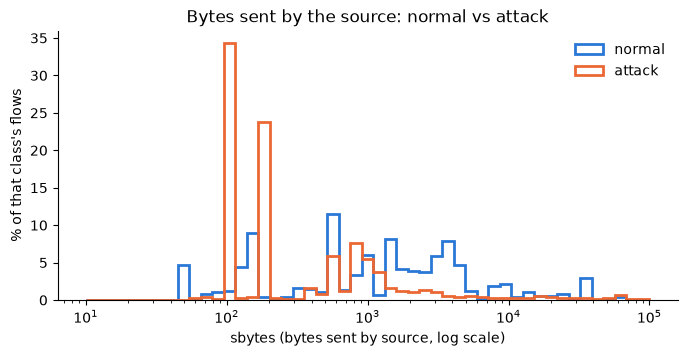

In [10]:
import numpy as np
import matplotlib.pyplot as plt

COLORS = {0: "#2a78d6", 1: "#eb6834"}  # normal = blue, attack = orange
NAMES = {0: "normal", 1: "attack"}

bins = np.logspace(1, 5, 50)  # 10 B .. 100 kB, evenly spaced on a log scale
fig, ax = plt.subplots(figsize=(8, 3.5))
for lbl in (0, 1):
    ax.hist(train.loc[train.label == lbl, "sbytes"], bins=bins, histtype="step",
            linewidth=2, color=COLORS[lbl], label=NAMES[lbl],
            weights=np.full((train.label == lbl).sum(), 100 / (train.label == lbl).sum()))
ax.set(xscale="log", xlabel="sbytes (bytes sent by source, log scale)", ylabel="% of that class's flows",
       title="Bytes sent by the source: normal vs attack")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 9. Which single feature separates the classes best?
A **decision stump** is a tree that asks exactly **one** question, e.g. *"is sbytes > 500?"*, and answers attack or normal. A Random Forest is built from hundreds of trees that ask many such questions, so a stump shows how much **one feature alone** can do.

We train a stump per feature on **train** and score it on **test** with **balanced accuracy**: the average of "% of normals caught" and "% of attacks caught". Guessing one class always scores 0.5, so 0.5 = useless, 1.0 = perfect.

(Only numeric features here; the text columns need encoding first.)

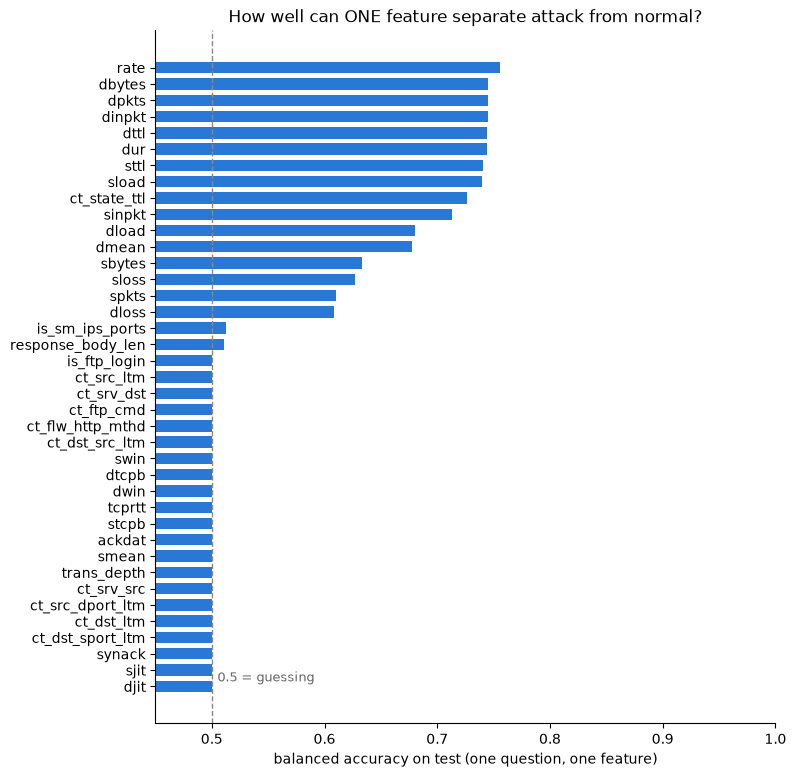

rate      0.756
dbytes    0.745
dpkts     0.745
dinpkt    0.745
dttl      0.744
dtype: float64

In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import balanced_accuracy_score

numeric = train.select_dtypes("number").columns.drop(["id", "label"])
scores = {}
for col in numeric:
    stump = DecisionTreeClassifier(max_depth=1).fit(train[[col]], train.label)
    scores[col] = balanced_accuracy_score(test.label, stump.predict(test[[col]]))
scores = pd.Series(scores).sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(scores.index, scores.values, color=COLORS[0], height=0.7)
ax.axvline(0.5, color="#888", linewidth=1, linestyle="--")
ax.text(0.505, 0.3, "0.5 = guessing", color="#666", fontsize=9)
ax.set(xlim=(0.45, 1), xlabel="balanced accuracy on test (one question, one feature)",
       title="How well can ONE feature separate attack from normal?")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
scores.sort_values(ascending=False).head(5).round(3)

## 10. A suspicious winner: `sttl`
`sttl` is the **TTL** (time-to-live) field of the source's packets. It is set by the sending machine's operating system, *not* by whether traffic is malicious. Let's see which values it takes per class.

In [12]:
pd.crosstab(train.sttl, train.label.map(NAMES)).query("attack + normal > 500")

label,attack,normal
sttl,,
0,303,2859
31,0,39455
62,15514,2167
254,103513,11230


Train says: TTL 31 → always normal, TTL 62/254 → mostly attack. That is an artefact of the **lab** where the data was recorded (attack machines had different operating systems), not a law of networks.

Does the shortcut hold on test? Compare the stump's score on both sets:

In [13]:
stump = DecisionTreeClassifier(max_depth=1).fit(train[["sttl"]], train.label)
print("rule learned: attack if sttl >", stump.tree_.threshold[0])
for name, df in [("train", train), ("test", test)]:
    print(f"{name}: {balanced_accuracy_score(df.label, stump.predict(df[['sttl']])):.3f}")

rule learned: attack if sttl > 61.0
train: 0.877
test: 0.740
